# 🔵 K-Means Clustering — Customer Segmentation
**Dataset:** Marketing Campaign (`marketing_campaign.csv`)  
**Tujuan:** Mengelompokkan pelanggan berdasarkan perilaku pembelian menggunakan K-Means Clustering  

---
## Tahapan:
1. Load & EDA
2. Preprocessing (Missing Value)
3. Feature Engineering
4. Outlier Handling (IQR Capping)
5. Encoding Kategorik
6. Feature Scaling
7. Penentuan K Optimal (Elbow + Silhouette)
8. K-Means Clustering
9. Evaluasi Metrik
10. Visualisasi & Cluster Profiling

## 1️⃣ Load Library & Dataset

In [84]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette('husl')

print('✅ Library berhasil di-import!')

✅ Library berhasil di-import!


In [85]:
dataset = pd.read_csv('../dataset/sentimen/marketing_campaign.csv', sep='\t')

pd.set_option('display.max_columns', None)

print(f'Shape dataset: {dataset.shape}')
dataset.head()

Shape dataset: (2240, 29)


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,88,546,172,88,88,3,8,10,4,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,1,6,2,1,6,2,1,1,2,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,49,127,111,21,42,1,8,2,10,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,4,20,10,3,5,2,2,0,4,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,43,118,46,27,15,5,5,3,6,5,0,0,0,0,0,0,3,11,0


In [86]:
dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   str    
 3   Marital_Status       2240 non-null   str    
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   str    
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 non-null   int64  
 16 

In [87]:
print('🔍 Missing Values per Kolom:')
missing = dataset.isnull().sum()
print(missing[missing > 0])
print(f'\nTotal missing values: {missing.sum()}')

🔍 Missing Values per Kolom:
Income    24
dtype: int64

Total missing values: 24


In [88]:
print('📊 Statistik Deskriptif:')
dataset.describe().round(2)

📊 Statistik Deskriptif:


,ID,Year_Birth,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
count,2240.00,2240.00,2216.00,2240.00,2240.00,2240.00,2240.00,2240.00,2240.00,2240.00,2240.00,2240.00,2240.00,2240.00,2240.00,2240.00,2240.00,2240.00,2240.00,2240.00,2240.00,2240.00,2240.00,2240.0,2240.0,2240.00
mean,5592.16,1968.81,52247.25,0.44,0.51,49.11,303.94,26.30,166.95,37.53,27.06,44.02,2.33,4.08,2.66,5.79,5.32,0.07,0.07,0.07,0.06,0.01,0.01,3.0,11.0,0.15
std,3246.66,11.98,25173.08,0.54,0.54,28.96,336.60,39.77,225.72,54.63,41.28,52.17,1.93,2.78,2.92,3.25,2.43,0.26,0.26,0.26,0.25,0.11,0.10,0.0,0.0,0.36
min,0.00,1893.00,1730.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,3.0,11.0,0.00
25%,2828.25,1959.00,35303.00,0.00,0.00,24.00,23.75,1.00,16.00,3.00,1.00,9.00,1.00,2.00,0.00,3.00,3.00,0.00,0.00,0.00,0.00,0.00,0.00,3.0,11.0,0.00
50%,5458.50,1970.00,51381.50,0.00,0.00,49.00,173.50,8.00,67.00,12.00,8.00,24.00,2.00,4.00,2.00,5.00,6.00,0.00,0.00,0.00,0.00,0.00,0.00,3.0,11.0,0.00
75%,8427.75,1977.00,68522.00,1.00,1.00,74.00,504.25,33.00,232.00,50.00,33.00,56.00,3.00,6.00,4.00,8.00,7.00,0.00,0.00,0.00,0.00,0.00,0.00,3.0,11.0,0.00
max,11191.00,1996.00,666666.00,2.00,2.00,99.00,1493.00,199.00,1725.00,259.00,263.00,362.00,15.00,27.00,28.00,13.00,20.00,1.00,1.00,1.00,1.00,1.00,1.00,3.0,11.0,1.00


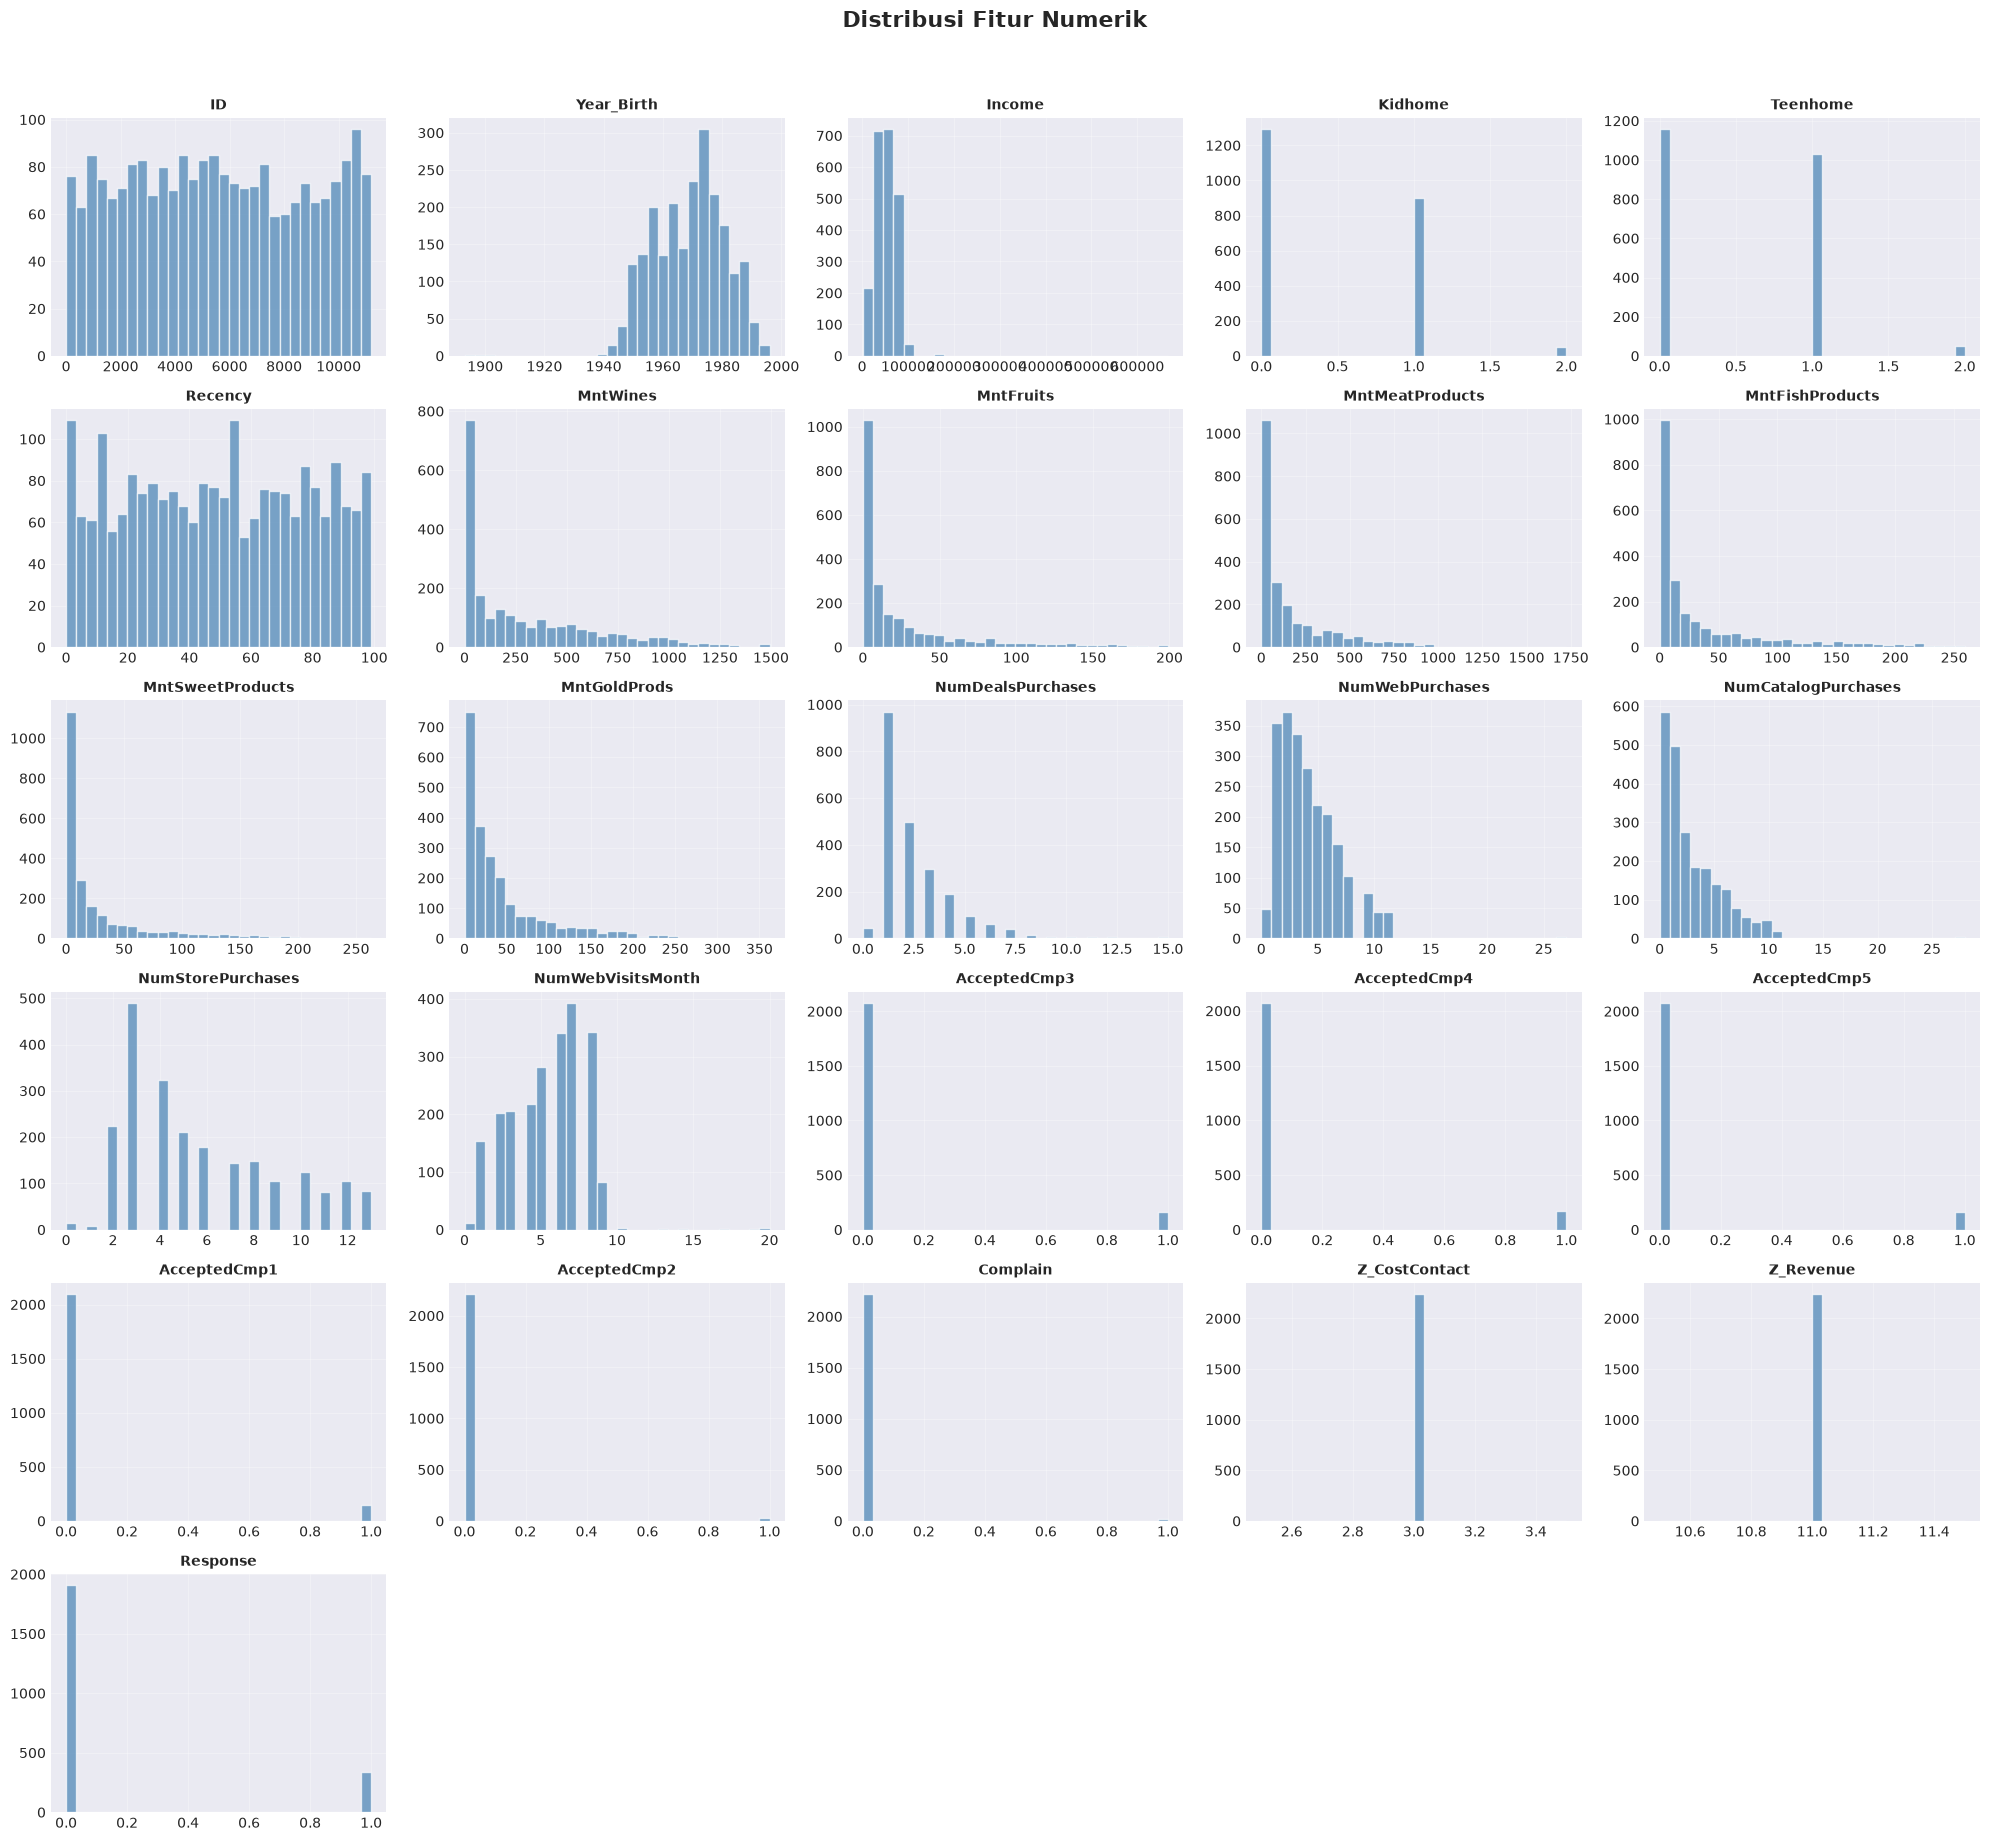

In [89]:
# Distribusi kolom numerik
num_cols = dataset.select_dtypes(include=[np.number]).columns.tolist()
n_cols = 5
n_rows = (len(num_cols) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, n_rows * 3))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    axes[i].hist(dataset[col].dropna(), bins=30, color='steelblue', alpha=0.7, edgecolor='white')
    axes[i].set_title(col, fontsize=10, fontweight='bold')
    axes[i].grid(True, alpha=0.3)

# Sembunyikan axes kosong
for j in range(i+1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Distribusi Fitur Numerik', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## 2️⃣ Preprocessing — Handle Missing Value

In [90]:
df = dataset.copy()

# ===== HANDLE MISSING VALUES =====
# Income: 24 missing value → isi dengan MEDIAN (robust terhadap outlier)
income_median = df['Income'].median()
df['Income'].fillna(income_median, inplace=True)
print(f'✅ Income missing values diisi dengan median: {income_median:,.2f}')

# ===== DROP KOLOM TIDAK RELEVAN =====
# ID         → hanya identifier, tidak bermakna untuk clustering
# Z_CostContact & Z_Revenue → konstan (nilai selalu 3 dan 11), tidak informatif
cols_to_drop = ['ID', 'Z_CostContact', 'Z_Revenue', 'Response']
df.drop(columns=cols_to_drop, inplace=True)
print(f'✅ Kolom dihapus: {cols_to_drop}')

print(f'\nShape setelah preprocessing: {df.shape}')
print(f'Total missing values tersisa: {df.isnull().sum().sum()}')

✅ Income missing values diisi dengan median: 51,381.50
✅ Kolom dihapus: ['ID', 'Z_CostContact', 'Z_Revenue', 'Response']

Shape setelah preprocessing: (2240, 25)
Total missing values tersisa: 24


## 3️⃣ Feature Engineering

In [91]:
# ===== FEATURE ENGINEERING =====

# 1. Usia pelanggan
df['Age'] = 2024 - df['Year_Birth']

# 2. Lama menjadi pelanggan (dalam hari)
df['Dt_Customer'] = pd.to_datetime(df['Dt_Customer'], format='%d-%m-%Y')
max_date = df['Dt_Customer'].max()
df['Customer_Days'] = (max_date - df['Dt_Customer']).dt.days

# 3. Total pengeluaran semua kategori produk
df['TotalSpending'] = (df['MntWines'] + df['MntFruits'] + df['MntMeatProducts'] +
                       df['MntFishProducts'] + df['MntSweetProducts'] + df['MntGoldProds'])

# 4. Total jumlah pembelian semua channel
df['TotalPurchases'] = (df['NumDealsPurchases'] + df['NumWebPurchases'] +
                        df['NumCatalogPurchases'] + df['NumStorePurchases'])

# 5. Total anak di rumah
df['TotalChildren'] = df['Kidhome'] + df['Teenhome']

# 6. Total kampanye yang diterima
df['TotalCampaignAccepted'] = (df['AcceptedCmp1'] + df['AcceptedCmp2'] +
                                df['AcceptedCmp3'] + df['AcceptedCmp4'] + df['AcceptedCmp5'])

# Drop kolom asli yang sudah di-aggregate
original_cols_to_drop = [
    'Year_Birth', 'Dt_Customer',
    'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds',
    'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases',
    'Kidhome', 'Teenhome',
    'AcceptedCmp1', 'AcceptedCmp2', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5'
]
df.drop(columns=original_cols_to_drop, inplace=True)

print('✅ Feature engineering selesai!')
print(f'Fitur baru: Age, Customer_Days, TotalSpending, TotalPurchases, TotalChildren, TotalCampaignAccepted')
print(f'Shape: {df.shape}')
print(f'\nKolom: {df.columns.tolist()}')
df.head()

✅ Feature engineering selesai!
Fitur baru: Age, Customer_Days, TotalSpending, TotalPurchases, TotalChildren, TotalCampaignAccepted
Shape: (2240, 12)

Kolom: ['Education', 'Marital_Status', 'Income', 'Recency', 'NumWebVisitsMonth', 'Complain', 'Age', 'Customer_Days', 'TotalSpending', 'TotalPurchases', 'TotalChildren', 'TotalCampaignAccepted']


,Education,Marital_Status,Income,Recency,NumWebVisitsMonth,Complain,Age,Customer_Days,TotalSpending,TotalPurchases,TotalChildren,TotalCampaignAccepted
0,Graduation,Single,58138.0,58,7,0,67,663,1617,25,0,0
1,Graduation,Single,46344.0,38,5,0,70,113,27,6,2,0
2,Graduation,Together,71613.0,26,4,0,59,312,776,21,0,0
3,Graduation,Together,26646.0,26,6,0,40,139,53,8,1,0
4,PhD,Married,58293.0,94,5,0,43,161,422,19,1,0


## 4️⃣ Encoding Variabel Kategorik

In [92]:
# ===== ENCODING KATEGORIK =====

# Education → Ordinal Encoding (ada urutan tingkat pendidikan)
education_order = {'Basic': 0, '2n Cycle': 1, 'Graduation': 2, 'Master': 3, 'PhD': 4}
df['Education'] = df['Education'].map(education_order)
print('Education value counts:')
print(df['Education'].value_counts())

# Marital Status → Nomor encoding
print('\nMarital Status unik:', df['Marital_Status'].unique())
marital_map = {'Single': 0, 'Divorced': 1, 'Widow': 2, 'Alone': 3,
               'Together': 4, 'Married': 5, 'Absurd': 6, 'YOLO': 7}
df['Marital_Status'] = df['Marital_Status'].map(marital_map)
print('\nMarital Status value counts:')
print(df['Marital_Status'].value_counts())

# Cek apakah ada NaN setelah encoding
print(f'\nNaN setelah encoding: {df.isnull().sum().sum()}')
print(f'Shape: {df.shape}')

Education value counts:
Education
2    1127
4     486
3     370
1     203
0      54
Name: count, dtype: int64

Marital Status unik: <StringArray>
['Single', 'Together', 'Married', 'Divorced', 'Widow', 'Alone', 'Absurd',
 'YOLO']
Length: 8, dtype: str

Marital Status value counts:
Marital_Status
5    864
4    580
0    480
1    232
2     77
3      3
6      2
7      2
Name: count, dtype: int64

NaN setelah encoding: 24
Shape: (2240, 12)


## 5️⃣ Outlier Handling — IQR Capping (Winsorizing)
> ⚠️ **K-Means sangat sensitif terhadap outlier** karena menggunakan jarak Euclidean dan rata-rata centroid. Outlier ekstrem dapat menarik centroid ke arah yang salah dan menghasilkan cluster yang tidak representatif.

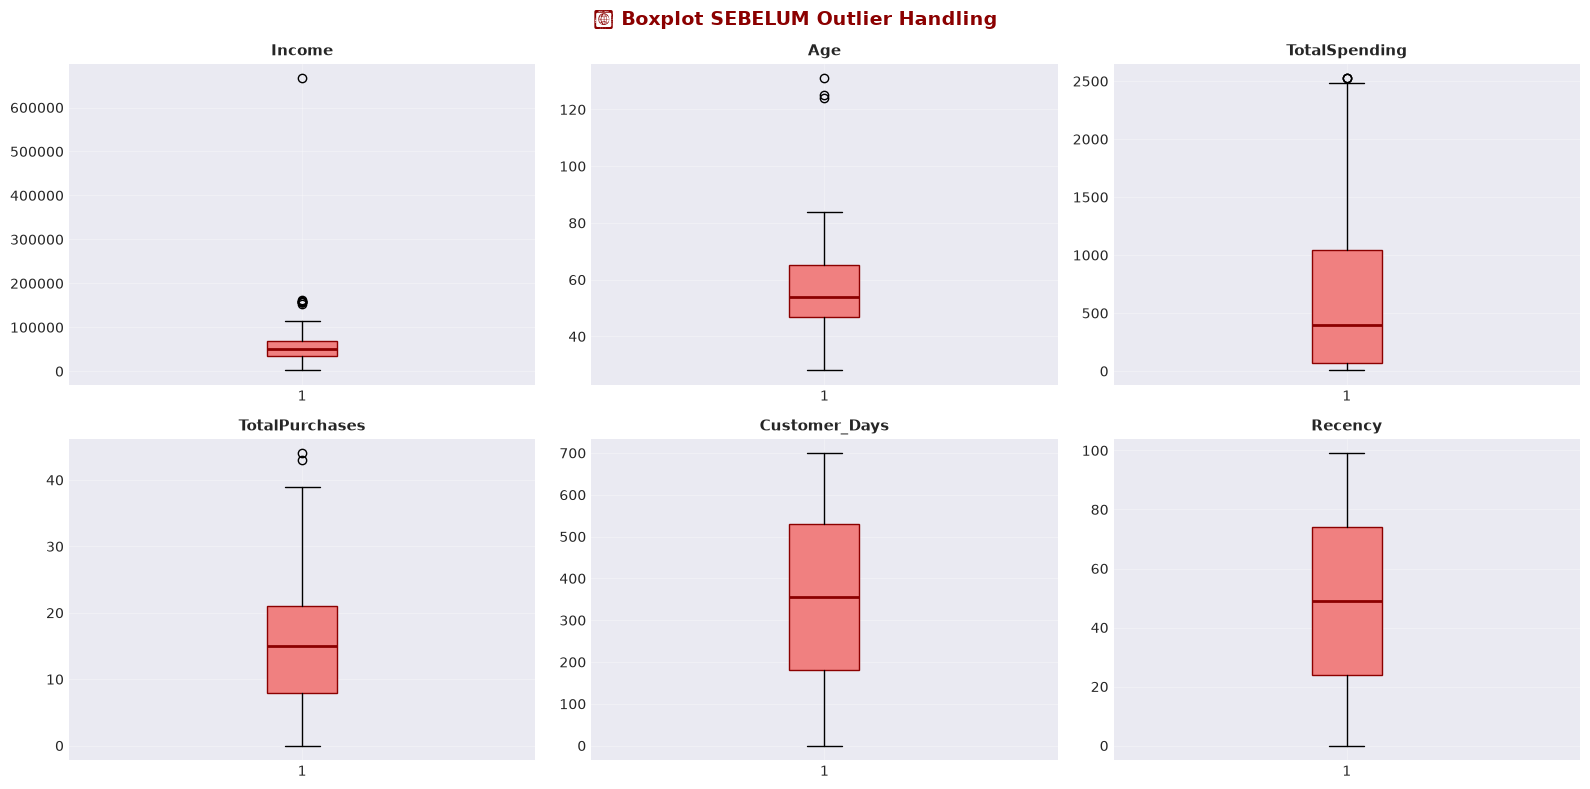

In [93]:
# Visualisasi outlier SEBELUM penanganan
key_features = ['Income', 'Age', 'TotalSpending', 'TotalPurchases', 'Customer_Days', 'Recency']

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()

for i, col in enumerate(key_features):
    axes[i].boxplot(df[col].dropna(), patch_artist=True,
                    boxprops=dict(facecolor='lightcoral', color='darkred'),
                    medianprops=dict(color='darkred', linewidth=2))
    axes[i].set_title(f'{col}', fontsize=11, fontweight='bold')
    axes[i].grid(True, alpha=0.3)

plt.suptitle('📦 Boxplot SEBELUM Outlier Handling', fontsize=14, fontweight='bold', color='darkred')
plt.tight_layout()
plt.show()

In [94]:
# ===== IQR CAPPING (WINSORIZING) =====
df_clean = df.copy()
numerical_cols = df_clean.select_dtypes(include=[np.number]).columns.tolist()

outlier_summary = []
for col in numerical_cols:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Hitung jumlah outlier
    n_outliers = ((df_clean[col] < lower_bound) | (df_clean[col] > upper_bound)).sum()

    # Capping
    df_clean[col] = df_clean[col].clip(lower=lower_bound, upper=upper_bound)

    outlier_summary.append({'Feature': col, 'N_Outliers': n_outliers,
                             'Lower': round(lower_bound, 2), 'Upper': round(upper_bound, 2)})

outlier_df = pd.DataFrame(outlier_summary)
print('📊 Ringkasan Outlier Handling (IQR Capping):')
print(outlier_df[outlier_df['N_Outliers'] > 0].to_string(index=False))
print(f'\n✅ Total outlier di-cap: {outlier_df["N_Outliers"].sum()} nilai')

📊 Ringkasan Outlier Handling (IQR Capping):
              Feature  N_Outliers     Lower     Upper
            Education          54      0.50      4.50
               Income           8 -14525.50 118350.50
    NumWebVisitsMonth           8     -3.00     13.00
             Complain          21      0.00      0.00
                  Age           3     20.00     92.00
        TotalSpending           3  -1396.38   2510.62
       TotalPurchases           2    -11.50     40.50
        TotalChildren          53     -1.50      2.50
TotalCampaignAccepted         463      0.00      0.00

✅ Total outlier di-cap: 615 nilai


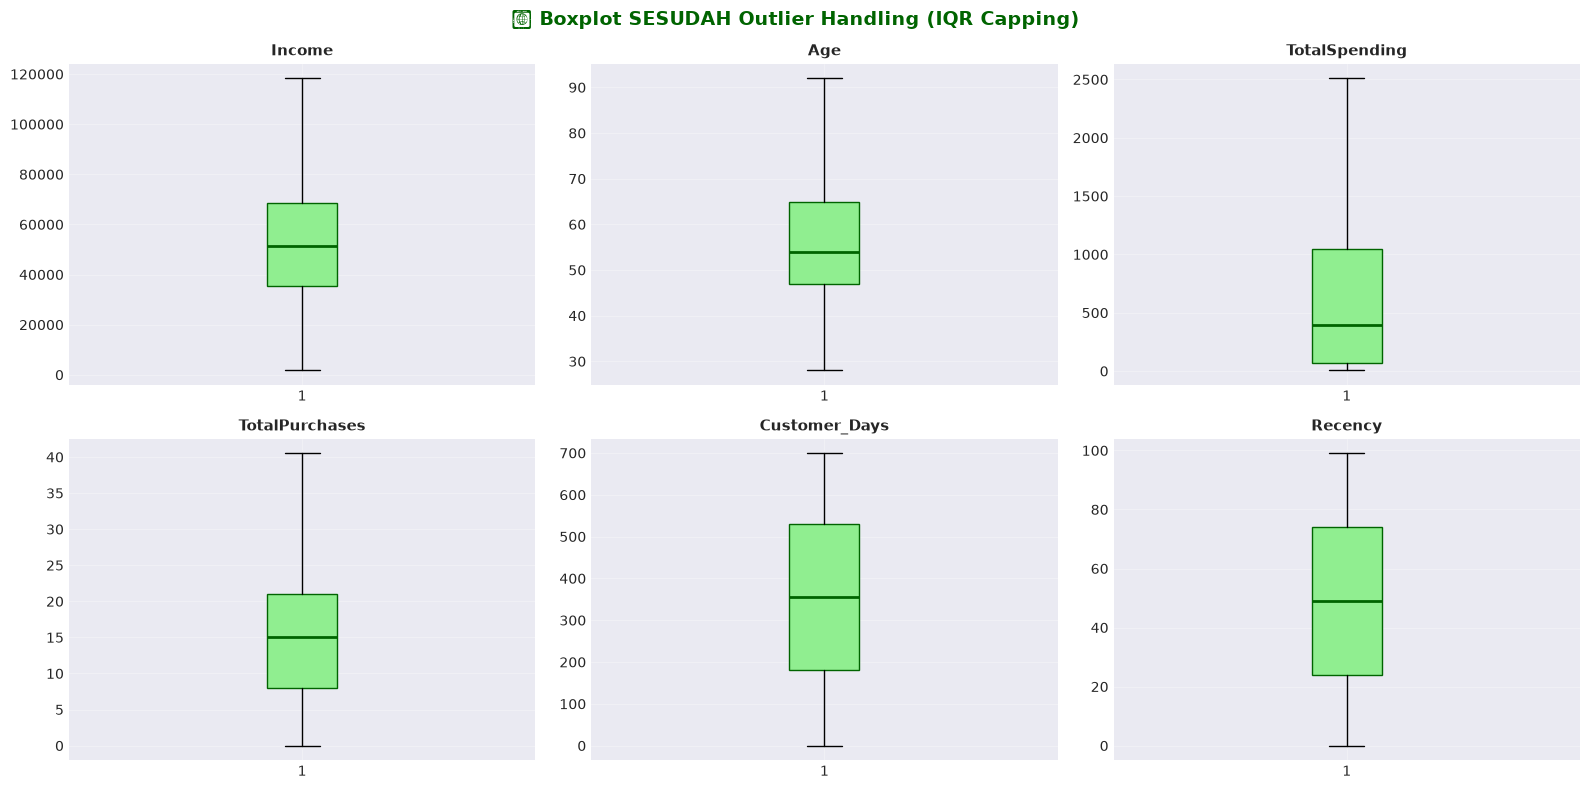

In [95]:
# Visualisasi SESUDAH outlier handling
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()

for i, col in enumerate(key_features):
    axes[i].boxplot(df_clean[col].dropna(), patch_artist=True,
                    boxprops=dict(facecolor='lightgreen', color='darkgreen'),
                    medianprops=dict(color='darkgreen', linewidth=2))
    axes[i].set_title(f'{col}', fontsize=11, fontweight='bold')
    axes[i].grid(True, alpha=0.3)

plt.suptitle('📦 Boxplot SESUDAH Outlier Handling (IQR Capping)', fontsize=14, fontweight='bold', color='darkgreen')
plt.tight_layout()
plt.show()

## 6️⃣ Feature Scaling — StandardScaler
> K-Means menggunakan jarak Euclidean, sehingga fitur dengan skala besar akan mendominasi. StandardScaler membuat semua fitur memiliki mean=0 dan std=1.

In [96]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_clean)
X_scaled_df = pd.DataFrame(X_scaled, columns=df_clean.columns)

# ── Bersihkan NaN/Inf akibat kolom zero-variance ──────────────────────────
# Kolom yang nilainya konstan (std=0) setelah IQR capping
# → StandardScaler menghasilkan NaN (0/0) → K-Means error!
# Solusi: drop kolom tersebut & ganti sisa NaN/Inf dengan 0

# 1. Drop kolom zero-variance
zero_var_cols = X_scaled_df.columns[X_scaled_df.var() == 0].tolist()
if zero_var_cols:
    print(f'⚠️  Kolom zero-variance di-drop setelah scaling: {zero_var_cols}')
    X_scaled_df = X_scaled_df.drop(columns=zero_var_cols)
else:
    print('✅ Tidak ada kolom zero-variance.')

# 2. Ganti NaN / Inf yang tersisa dengan 0
n_nan = X_scaled_df.isnull().sum().sum()
n_inf = np.isinf(X_scaled_df.values).sum()
if n_nan > 0 or n_inf > 0:
    print(f'⚠️  Ditemukan {n_nan} NaN dan {n_inf} Inf → diganti 0')
    X_scaled_df = X_scaled_df.replace([np.inf, -np.inf], np.nan).fillna(0)
else:
    print('✅ Tidak ada NaN/Inf di data.')

print(f'\n✅ Feature Scaling (StandardScaler) selesai!')
print(f'Shape: {X_scaled_df.shape}')
print('\nStatistik setelah scaling (seharusnya mean≈0, std≈1):')
print(X_scaled_df.describe().round(3))

⚠️  Kolom zero-variance di-drop setelah scaling: ['Complain', 'TotalCampaignAccepted']
⚠️  Ditemukan 24 NaN dan 0 Inf → diganti 0

✅ Feature Scaling (StandardScaler) selesai!
Shape: (2240, 10)

Statistik setelah scaling (seharusnya mean≈0, std≈1):
       Education  Marital_Status    Income   Recency  NumWebVisitsMonth  \
count   2240.000        2240.000  2240.000  2240.000           2240.000   
mean       0.000           0.000     0.000    -0.000             -0.000   
std        1.000           1.000     0.995     1.000              1.000   
min       -2.018          -1.542    -2.382    -1.696             -2.257   
25%       -0.483          -1.053    -0.776    -0.867             -0.979   
50%       -0.483           0.415    -0.006    -0.004              0.299   
75%        0.540           0.904     0.780     0.860              0.724   
max        1.563           1.882     3.157     1.723              3.280   

            Age  Customer_Days  TotalSpending  TotalPurchases  TotalChildren

## 7️⃣ Menentukan K Optimal

K=2: Inertia = 16766.43
K=3: Inertia = 15273.65
K=4: Inertia = 14095.33
K=5: Inertia = 13335.61
K=6: Inertia = 12763.99
K=7: Inertia = 12279.52
K=8: Inertia = 11903.80
K=9: Inertia = 11459.83
K=10: Inertia = 11171.82


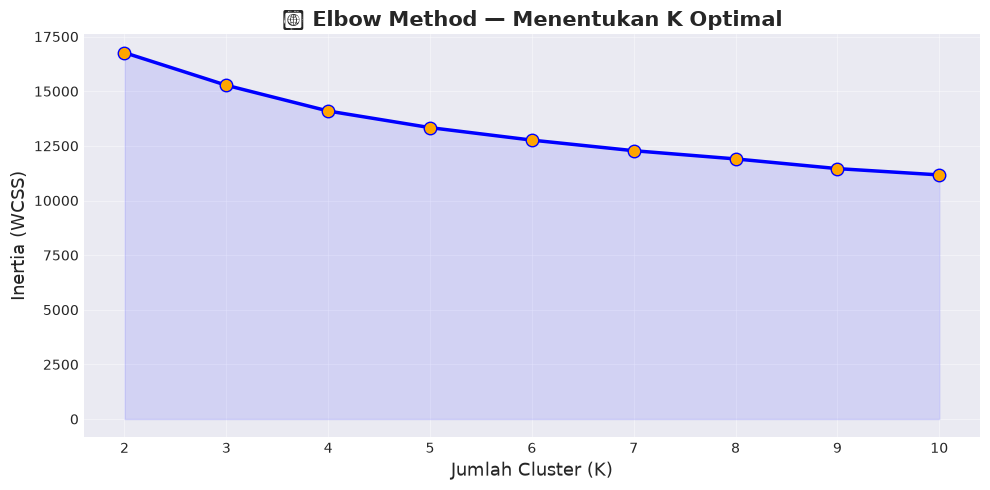

In [97]:
# ===== ELBOW METHOD =====
K_range = range(2, 11)
inertia = []

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled_df)
    inertia.append(kmeans.inertia_)
    print(f'K={k}: Inertia = {kmeans.inertia_:.2f}')

plt.figure(figsize=(10, 5))
plt.plot(K_range, inertia, 'bo-', linewidth=2.5, markersize=9, markerfacecolor='orange')
plt.fill_between(K_range, inertia, alpha=0.1, color='blue')
plt.xlabel('Jumlah Cluster (K)', fontsize=13)
plt.ylabel('Inertia (WCSS)', fontsize=13)
plt.title('📐 Elbow Method — Menentukan K Optimal', fontsize=15, fontweight='bold')
plt.xticks(K_range)
plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()

K=2 | Silhouette=0.2274 | Davies-Bouldin=1.6872 | Calinski-Harabasz=748.77
K=3 | Silhouette=0.1598 | Davies-Bouldin=2.0066 | Calinski-Harabasz=520.11
K=4 | Silhouette=0.1385 | Davies-Bouldin=2.1161 | Calinski-Harabasz=437.87
K=5 | Silhouette=0.1366 | Davies-Bouldin=2.0206 | Calinski-Harabasz=378.78
K=6 | Silhouette=0.1271 | Davies-Bouldin=2.0767 | Calinski-Harabasz=336.47
K=7 | Silhouette=0.1290 | Davies-Bouldin=2.1327 | Calinski-Harabasz=306.00
K=8 | Silhouette=0.1165 | Davies-Bouldin=2.1302 | Calinski-Harabasz=280.51
K=9 | Silhouette=0.1206 | Davies-Bouldin=2.0225 | Calinski-Harabasz=265.64
K=10 | Silhouette=0.1201 | Davies-Bouldin=1.9665 | Calinski-Harabasz=248.50


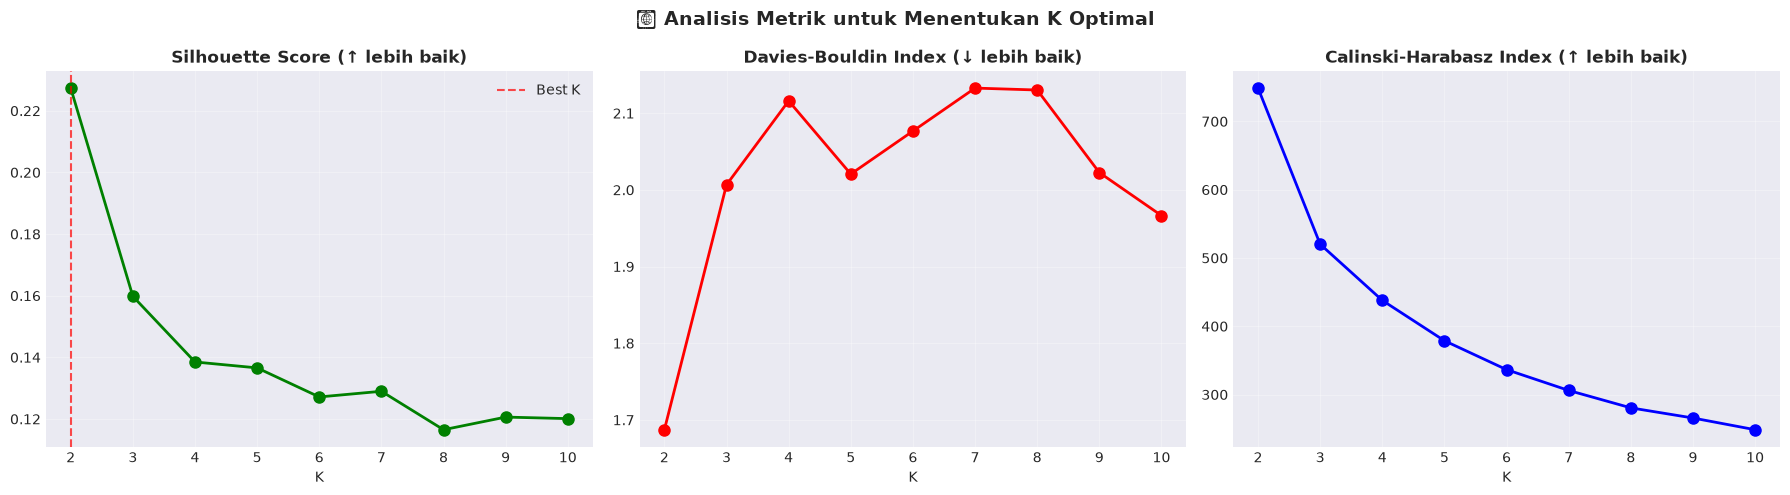


🏆 K optimal berdasarkan Silhouette Score terbaik: K = 2


In [98]:
# ===== SILHOUETTE SCORE ANALYSIS =====
silhouette_scores = []
db_scores = []
ch_scores = []

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled_df)

    sil = silhouette_score(X_scaled_df, labels)
    db  = davies_bouldin_score(X_scaled_df, labels)
    ch  = calinski_harabasz_score(X_scaled_df, labels)

    silhouette_scores.append(sil)
    db_scores.append(db)
    ch_scores.append(ch)

    print(f'K={k} | Silhouette={sil:.4f} | Davies-Bouldin={db:.4f} | Calinski-Harabasz={ch:.2f}')

# Plot semua metrik
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(K_range, silhouette_scores, 'go-', linewidth=2, markersize=8)
axes[0].set_title('Silhouette Score (↑ lebih baik)', fontweight='bold')
axes[0].set_xlabel('K'); axes[0].set_xticks(K_range); axes[0].grid(True, alpha=0.3)
axes[0].axvline(x=list(K_range)[silhouette_scores.index(max(silhouette_scores))],
                color='red', linestyle='--', alpha=0.7, label='Best K')
axes[0].legend()

axes[1].plot(K_range, db_scores, 'ro-', linewidth=2, markersize=8)
axes[1].set_title('Davies-Bouldin Index (↓ lebih baik)', fontweight='bold')
axes[1].set_xlabel('K'); axes[1].set_xticks(K_range); axes[1].grid(True, alpha=0.3)

axes[2].plot(K_range, ch_scores, 'bo-', linewidth=2, markersize=8)
axes[2].set_title('Calinski-Harabasz Index (↑ lebih baik)', fontweight='bold')
axes[2].set_xlabel('K'); axes[2].set_xticks(K_range); axes[2].grid(True, alpha=0.3)

plt.suptitle('📊 Analisis Metrik untuk Menentukan K Optimal', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

best_k = list(K_range)[silhouette_scores.index(max(silhouette_scores))]
print(f'\n🏆 K optimal berdasarkan Silhouette Score terbaik: K = {best_k}')

## 8️⃣ K-Means Clustering — Model Final

In [99]:
# ===== K-MEANS FINAL MODEL =====
print(f'Melatih K-Means dengan K={best_k}...')

kmeans_final = KMeans(
    n_clusters=best_k,
    init='k-means++',      # Inisialisasi cerdas untuk konvergensi lebih cepat
    n_init=10,             # Jalankan 10 kali dengan inisialisasi berbeda
    max_iter=300,
    random_state=42
)

cluster_labels = kmeans_final.fit_predict(X_scaled_df)

# Tambahkan label cluster ke dataframe asli
df_result = df.copy()
df_result['Cluster'] = cluster_labels

print(f'✅ K-Means selesai dilatih!')
print(f'\n📊 Distribusi Cluster:')
dist = df_result['Cluster'].value_counts().sort_index()
for cluster, count in dist.items():
    print(f'  Cluster {cluster}: {count} pelanggan ({count/len(df_result)*100:.1f}%)')

Melatih K-Means dengan K=2...
✅ K-Means selesai dilatih!

📊 Distribusi Cluster:
  Cluster 0: 1248 pelanggan (55.7%)
  Cluster 1: 992 pelanggan (44.3%)


## 9️⃣ Evaluasi Metrik Clustering

In [100]:
# ===== EVALUASI METRIK =====
sil_score_final = silhouette_score(X_scaled_df, cluster_labels)
db_score_final  = davies_bouldin_score(X_scaled_df, cluster_labels)
ch_score_final  = calinski_harabasz_score(X_scaled_df, cluster_labels)
inertia_final   = kmeans_final.inertia_

print('=' * 60)
print('  📈 EVALUASI K-MEANS CLUSTERING')
print('=' * 60)
print(f'  Jumlah Cluster (K)   : {best_k}')
print(f'  Total Data           : {len(df_result)}')
print('-' * 60)
print(f'  ✅ Silhouette Score  : {sil_score_final:.4f}')
print(f'     → Mendekati 1 = cluster semakin terpisah dan padat')
print(f'     → Range: -1 (buruk) hingga 1 (sempurna)')
print()
print(f'  ✅ Davies-Bouldin    : {db_score_final:.4f}')
print(f'     → Semakin kecil = cluster lebih terpisah')
print(f'     → Nilai ideal = 0')
print()
print(f'  ✅ Calinski-Harabasz : {ch_score_final:.4f}')
print(f'     → Semakin besar = cluster lebih padat dan terpisah')
print()
print(f'  ✅ Inertia (WCSS)    : {inertia_final:.4f}')
print(f'     → Semakin kecil = titik dalam cluster lebih dekat ke centroid')
print('=' * 60)

  📈 EVALUASI K-MEANS CLUSTERING
  Jumlah Cluster (K)   : 2
  Total Data           : 2240
------------------------------------------------------------
  ✅ Silhouette Score  : 0.2274
     → Mendekati 1 = cluster semakin terpisah dan padat
     → Range: -1 (buruk) hingga 1 (sempurna)

  ✅ Davies-Bouldin    : 1.6872
     → Semakin kecil = cluster lebih terpisah
     → Nilai ideal = 0

  ✅ Calinski-Harabasz : 748.7738
     → Semakin besar = cluster lebih padat dan terpisah

  ✅ Inertia (WCSS)    : 16766.4280
     → Semakin kecil = titik dalam cluster lebih dekat ke centroid


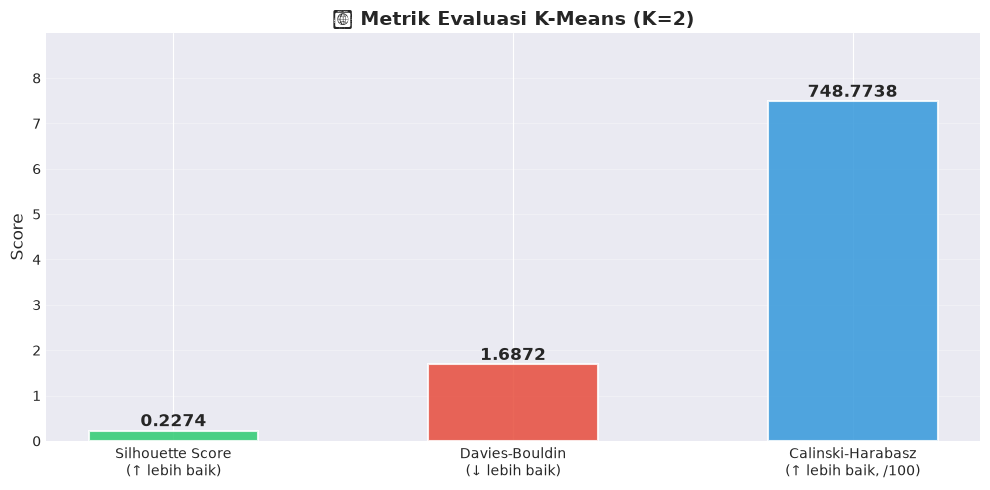

In [101]:
# Visualisasi metrik evaluasi
metrics_names = ['Silhouette Score\n(↑ lebih baik)', 'Davies-Bouldin\n(↓ lebih baik)', 'Calinski-Harabasz\n(↑ lebih baik, /100)']
metrics_values = [sil_score_final, db_score_final, ch_score_final / 100]
colors_bar = ['#2ecc71', '#e74c3c', '#3498db']

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(metrics_names, metrics_values, color=colors_bar, alpha=0.85,
              edgecolor='white', linewidth=1.5, width=0.5)

for bar, val, orig in zip(bars, metrics_values, [sil_score_final, db_score_final, ch_score_final]):
    ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.01,
            f'{orig:.4f}', ha='center', va='bottom', fontsize=12, fontweight='bold')

ax.set_title(f'📊 Metrik Evaluasi K-Means (K={best_k})', fontsize=14, fontweight='bold')
ax.set_ylabel('Score', fontsize=12)
ax.grid(True, alpha=0.3, axis='y')
ax.set_ylim(0, max(metrics_values) * 1.2)
plt.tight_layout()
plt.show()

## 🔟 Visualisasi Cluster — PCA 2D

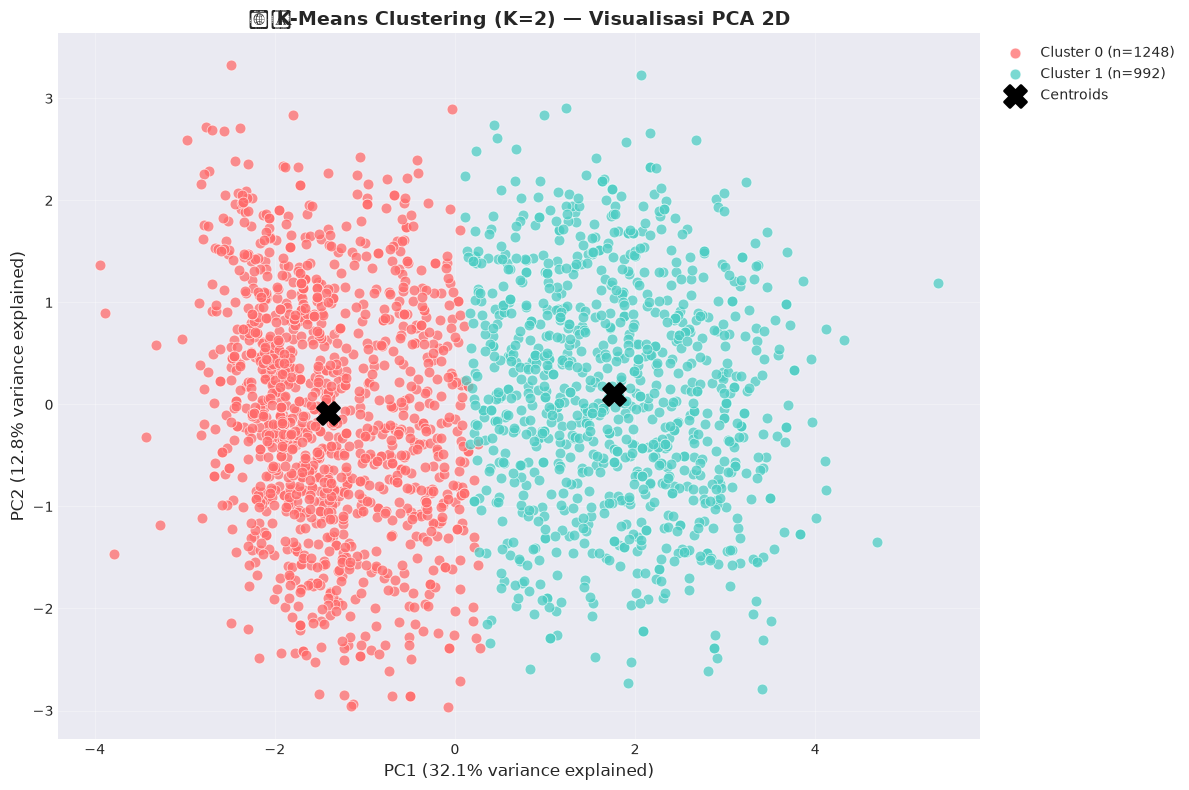

Total variance explained oleh 2 PC: 44.96%


In [102]:
# ===== VISUALISASI PCA 2D =====
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled_df)

cluster_colors = ['#FF6B6B', '#4ECDC4', '#45B7D1', '#96CEB4', '#FFEAA7', '#DDA0DD', '#F8B4D9', '#AED6F1']

plt.figure(figsize=(12, 8))
for cluster in range(best_k):
    mask = cluster_labels == cluster
    plt.scatter(X_pca[mask, 0], X_pca[mask, 1],
                c=cluster_colors[cluster], label=f'Cluster {cluster} (n={mask.sum()})',
                s=60, alpha=0.75, edgecolors='white', linewidth=0.5)

# Plot centroids
centroids_pca = pca.transform(kmeans_final.cluster_centers_)
plt.scatter(centroids_pca[:, 0], centroids_pca[:, 1],
            c='black', marker='X', s=250, zorder=10, label='Centroids', linewidths=2)

plt.title(f'🗺️ K-Means Clustering (K={best_k}) — Visualisasi PCA 2D', fontsize=14, fontweight='bold')
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance explained)', fontsize=12)
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance explained)', fontsize=12)
plt.legend(fontsize=10, bbox_to_anchor=(1.01, 1), loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

total_var = sum(pca.explained_variance_ratio_) * 100
print(f'Total variance explained oleh 2 PC: {total_var:.2f}%')

In [103]:
# ===== CLUSTER PROFILING =====
profiling_features = ['Income', 'Age', 'TotalSpending', 'TotalPurchases',
                      'TotalChildren', 'TotalCampaignAccepted', 'Customer_Days', 'Recency', 'NumWebVisitsMonth']

cluster_profile = df_result.groupby('Cluster')[profiling_features].mean().round(2)
print('📊 CLUSTER PROFILING — K-MEANS')
print('=' * 80)
print(cluster_profile.T)

# Simpan metrik evaluasi untuk perbandingan nanti
kmeans_metrics = {
    'Model': 'K-Means',
    'N_Clusters': best_k,
    'Silhouette Score': round(sil_score_final, 4),
    'Davies-Bouldin': round(db_score_final, 4),
    'Calinski-Harabasz': round(ch_score_final, 2)
}
print(f'\n✅ Metrik K-Means disimpan untuk perbandingan: {kmeans_metrics}')

📊 CLUSTER PROFILING — K-MEANS
Cluster                       0         1
Income                 36803.67  71583.12
Age                       53.49     57.34
TotalSpending            158.61   1168.39
TotalPurchases             9.70     21.35
TotalChildren              1.27      0.55
TotalCampaignAccepted      0.11      0.54
Customer_Days            339.41    371.42
Recency                   48.85     49.43
NumWebVisitsMonth          6.54      3.77

✅ Metrik K-Means disimpan untuk perbandingan: {'Model': 'K-Means', 'N_Clusters': 2, 'Silhouette Score': 0.2274, 'Davies-Bouldin': 1.6872, 'Calinski-Harabasz': 748.77}


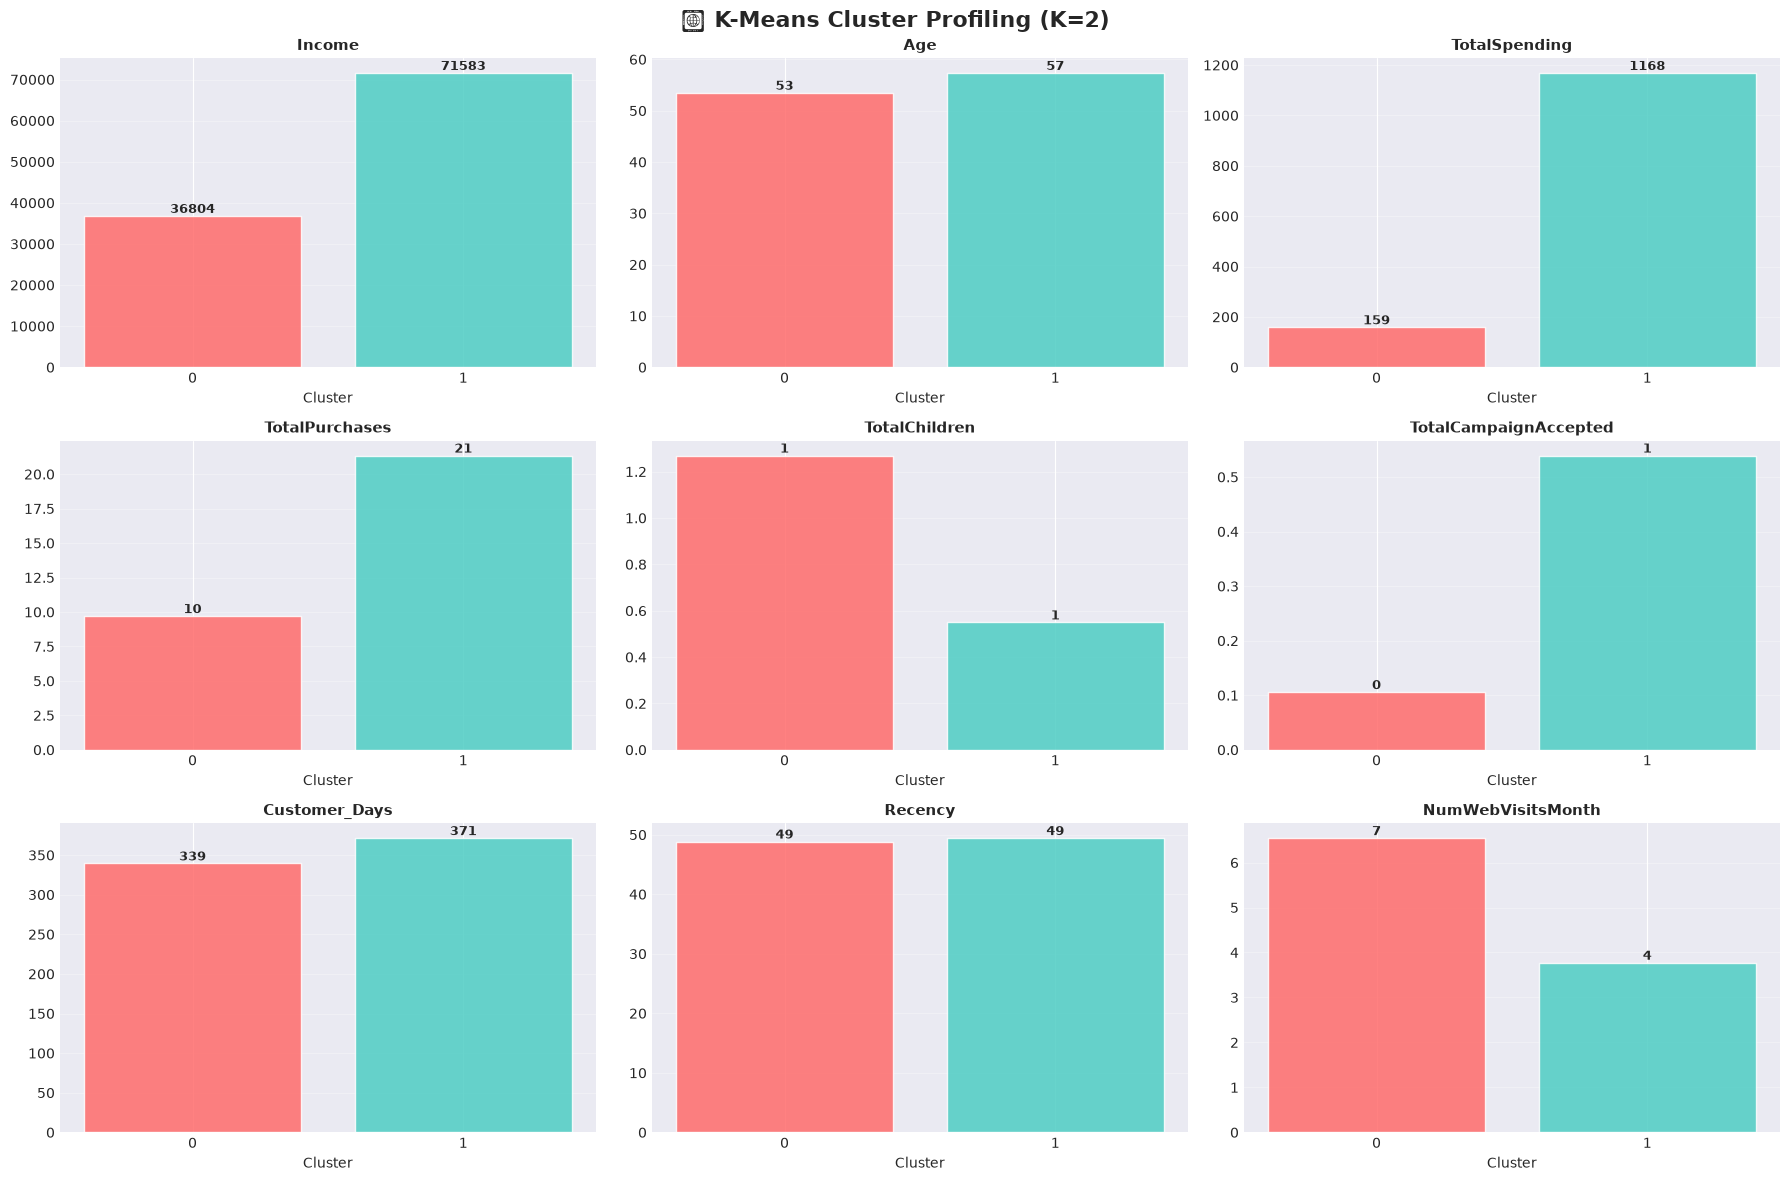

In [104]:
# Visualisasi profil cluster per fitur
n_feat = len(profiling_features)
n_cols_fig = 3
n_rows_fig = (n_feat + n_cols_fig - 1) // n_cols_fig

fig, axes = plt.subplots(n_rows_fig, n_cols_fig, figsize=(18, n_rows_fig * 4))
axes = axes.flatten()

for i, feat in enumerate(profiling_features):
    cluster_means = df_result.groupby('Cluster')[feat].mean()
    bars = axes[i].bar(cluster_means.index.astype(str),
                       cluster_means.values,
                       color=[cluster_colors[j] for j in cluster_means.index],
                       alpha=0.85, edgecolor='white', linewidth=1)
    axes[i].set_title(f'{feat}', fontsize=11, fontweight='bold')
    axes[i].set_xlabel('Cluster')
    axes[i].grid(True, alpha=0.3, axis='y')
    for bar, val in zip(bars, cluster_means.values):
        axes[i].text(bar.get_x() + bar.get_width()/2., bar.get_height(),
                     f'{val:.0f}', ha='center', va='bottom', fontsize=9, fontweight='bold')

for j in range(i+1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle(f'📊 K-Means Cluster Profiling (K={best_k})', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

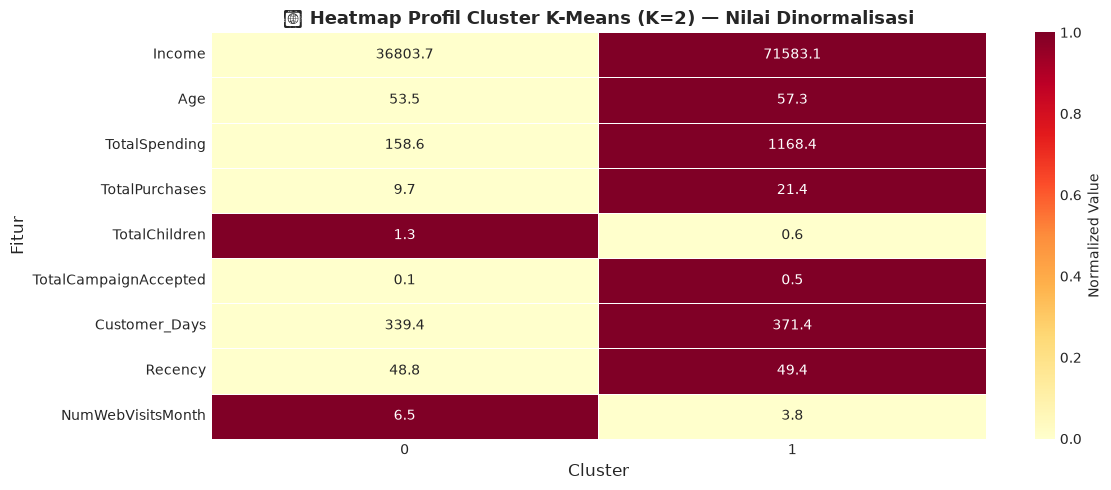


✅ K-Means Clustering selesai!
📁 Lihat file hierarchical_clustering.ipynb untuk model Hierarchical Agglomerative Clustering.


In [105]:
# Heatmap profil cluster (normalized)
profile_norm = (cluster_profile - cluster_profile.min()) / (cluster_profile.max() - cluster_profile.min())

plt.figure(figsize=(12, 5))
sns.heatmap(profile_norm.T, annot=cluster_profile.T.round(1), fmt='g',
            cmap='YlOrRd', linewidths=0.5, linecolor='white',
            cbar_kws={'label': 'Normalized Value'})
plt.title(f'🔥 Heatmap Profil Cluster K-Means (K={best_k}) — Nilai Dinormalisasi', fontsize=13, fontweight='bold')
plt.xlabel('Cluster', fontsize=12)
plt.ylabel('Fitur', fontsize=12)
plt.tight_layout()
plt.show()

print('\n✅ K-Means Clustering selesai!')
print('📁 Lihat file hierarchical_clustering.ipynb untuk model Hierarchical Agglomerative Clustering.')